# Customer Churn Prediction Using Machine Learning
**Artificial Intelligence – Assignment 1**  
**Dataset:** Telco Customer Churn (provided CSV)  
**Objective:** Build an end-to-end machine learning system to predict whether a telecom customer will churn.

> **Dataset format note:** The assignment brief names an Excel file, but the supplied dataset is a CSV file. This notebook uses the supplied CSV without changing the underlying records.


In [1]:
# 1. Import libraries and load the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

pd.set_option('display.max_columns', None)

DATA_PATH = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data Understanding
The target variable is **Churn**. It indicates whether a customer left the telecom company (`Yes`) or stayed (`No`). Important columns include tenure, contract type, internet service, monthly charges, total charges, and payment method.

In [2]:
# Column names, data types, and basic statistics
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame('dtype'))

print("\nBasic statistics:")
display(df.describe(include='all').T)


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Basic statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Target distribution
print("Target variable: Churn")
display(df['Churn'].value_counts())
display(df['Churn'].value_counts(normalize=True).mul(100).round(2).rename('percentage'))


Target variable: Churn


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.46
Yes    26.54
Name: percentage, dtype: float64

## 3. Data Preprocessing
Steps:
1. Convert `TotalCharges` from text to numeric because it contains values that need numeric analysis.
2. Treat the resulting blank/non-numeric values as missing and impute them with the median.
3. Check duplicate records and remove exact duplicates if present.
4. Drop `customerID` because it is an identifier, not a useful predictive feature.
5. Create `TenureYears` as a simple derived feature.
6. Encode categorical features with one-hot encoding and scale numeric features for Logistic Regression.

In [4]:
# Data quality checks
print("Missing values before cleaning:")
display(df.isna().sum().sort_values(ascending=False).head(10))

print("Duplicate rows:", df.duplicated().sum())

# Convert TotalCharges to numeric; invalid/blank values become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("\nMissing values after converting TotalCharges:")
display(df.isna().sum().sort_values(ascending=False).head(10))

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Feature engineering
df['TenureYears'] = df['tenure'] / 12

# Encode target
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

print("\nCleaned shape:", df.shape)
print("Remaining missing TotalCharges:", df['TotalCharges'].isna().sum())


Missing values before cleaning:


customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64

Duplicate rows: 0

Missing values after converting TotalCharges:


TotalCharges      11
gender             0
SeniorCitizen      0
Partner            0
customerID         0
Dependents         0
tenure             0
MultipleLines      0
PhoneService       0
OnlineSecurity     0
dtype: int64


Cleaned shape: (7043, 22)
Remaining missing TotalCharges: 11


## 4. Exploratory Data Analysis
The following visualizations examine overall churn and relationships between churn and customer characteristics.

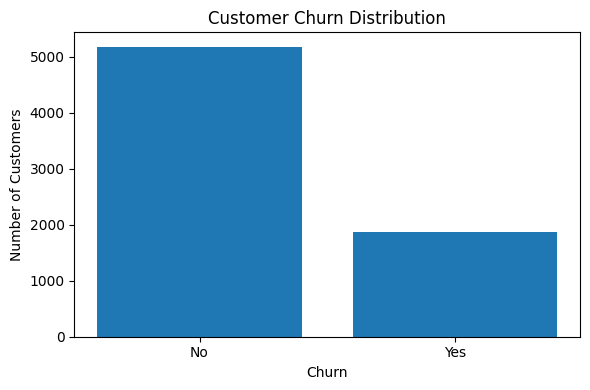

In [5]:
# Churn distribution
counts = df['Churn'].map({0:'No',1:'Yes'}).value_counts().reindex(['No','Yes'])
plt.figure(figsize=(6,4))
plt.bar(counts.index, counts.values)
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


,No Churn %,Churn %
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


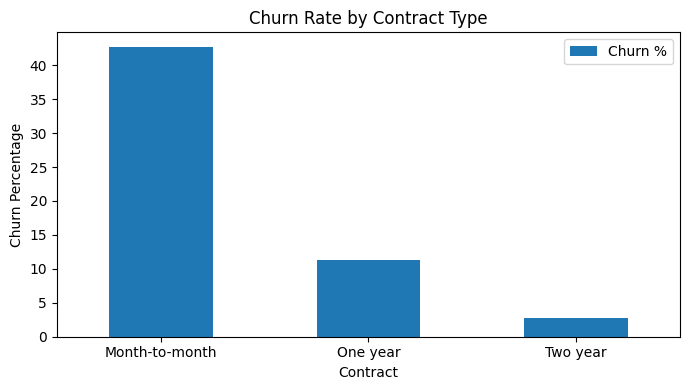

In [6]:
# Churn by contract type
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contract_churn.columns = ['No Churn %', 'Churn %']
display(contract_churn.round(2))

contract_churn[['Churn %']].plot(kind='bar', figsize=(7,4))
plt.title('Churn Rate by Contract Type')
plt.ylabel('Churn Percentage')
plt.xlabel('Contract')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


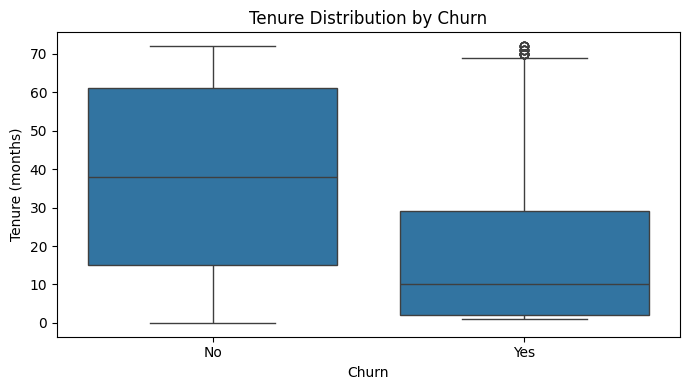

In [7]:
# Churn by tenure
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x=df['Churn'].map({0:'No',1:'Yes'}), y='tenure')
plt.title('Tenure Distribution by Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (months)')
plt.tight_layout()
plt.show()


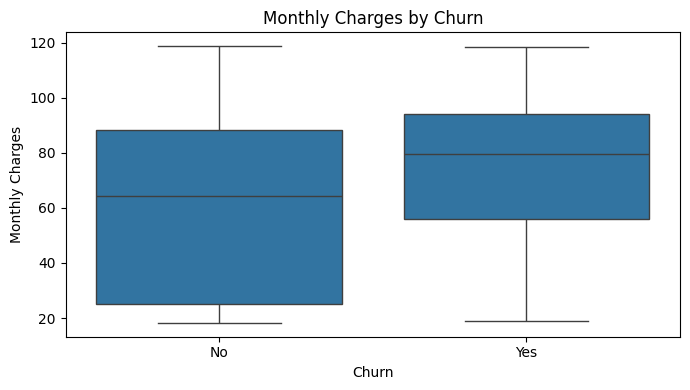

In [8]:
# Churn by monthly charges
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x=df['Churn'].map({0:'No',1:'Yes'}), y='MonthlyCharges')
plt.title('Monthly Charges by Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.tight_layout()
plt.show()


## 5. Feature Engineering, Encoding, Training and Testing
`customerID` is removed because it uniquely identifies customers and does not describe customer behavior. The remaining columns are separated into numeric and categorical groups. A preprocessing pipeline handles missing numeric values, scaling, and one-hot encoding.

Two classification algorithms are trained:
- **Logistic Regression** – a simple and interpretable classification baseline.
- **Random Forest** – an ensemble of decision trees that can capture non-linear relationships.

In [9]:
# Separate features X and target y
X = df.drop(columns=['Churn', 'customerID'])
y = df['Churn']

numeric_features = X.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight='balanced'
    ))
])

logistic_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("Both models trained successfully.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TenureYears']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Both models trained successfully.
Training samples: 5634
Testing samples: 1409


In [10]:
# 6. Model Evaluation
def evaluate_model(name, model):
    pred = model.predict(X_test)
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-Score': f1_score(y_test, pred, zero_division=0)
    }
    print(f"\n{name} Classification Report:")
    print(classification_report(y_test, pred, target_names=['No Churn','Churn'], zero_division=0))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, pred))
    return metrics, pred

log_metrics, log_pred = evaluate_model("Logistic Regression", logistic_model)
rf_metrics, rf_pred = evaluate_model("Random Forest", rf_model)

results = pd.DataFrame([log_metrics, rf_metrics])
display(results.round(4))



Logistic Regression Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[926 109]
 [165 209]]

Random Forest Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1035
       Churn       0.64      0.48      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409

Confusion Matrix:
[[931 104]
 [193 181]]


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,Random Forest,0.7892,0.6351,0.4840,0.5493


/tmp/ipykernel_511/310696832.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


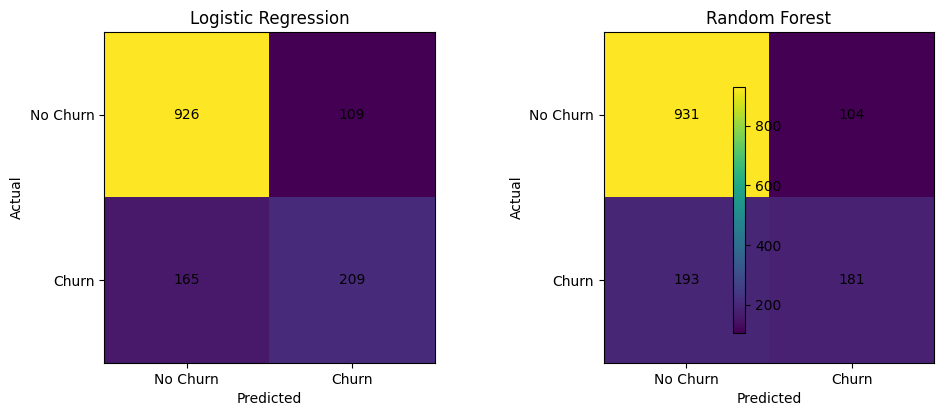

In [11]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10,4))
for ax, cm, title in [
    (axes[0], confusion_matrix(y_test, log_pred), 'Logistic Regression'),
    (axes[1], confusion_matrix(y_test, rf_pred), 'Random Forest')
]:
    im = ax.imshow(cm)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(['No Churn','Churn'])
    ax.set_yticklabels(['No Churn','Churn'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i,j], ha='center', va='center')
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8)
plt.tight_layout()
plt.show()


## 7. Final Model and Sample Prediction
For the demonstration prediction below, the model with the higher F1-score on the test set is selected. The sample represents a customer profile and the system returns a **Churn** or **No Churn** prediction.

In [12]:
# Select model using test-set F1 score
if rf_metrics['F1-Score'] >= log_metrics['F1-Score']:
    final_model = rf_model
    final_model_name = 'Random Forest'
else:
    final_model = logistic_model
    final_model_name = 'Logistic Regression'

print("Selected final model:", final_model_name)

sample_customer = X_test.iloc[[0]].copy()
sample_prediction = final_model.predict(sample_customer)[0]
sample_probability = final_model.predict_proba(sample_customer)[0, 1]

display(sample_customer)
print("Predicted result:", "Churn" if sample_prediction == 1 else "No Churn")
print(f"Predicted churn probability: {sample_probability:.2%}")


Selected final model: Logistic Regression


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,TenureYears
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2,6.0


Predicted result: No Churn
Predicted churn probability: 4.55%


## 8. Conclusion
The notebook completes the requested churn-prediction pipeline: loading and understanding the data, cleaning and preprocessing, EDA, feature engineering, categorical encoding, train/test split, training two classifiers, evaluation, comparison, and an example prediction. The final report discusses observations, limitations, and possible telecom business use.

In [13]:
# Compact final summary for the report
print("FINAL SUMMARY")
print("Dataset shape:", df.shape)
print("Churn rate:", f"{y.mean():.2%}")
print("Best model by F1-score:", final_model_name)
display(results.round(4))


FINAL SUMMARY
Dataset shape: (7043, 22)
Churn rate: 26.54%
Best model by F1-score: Logistic Regression


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,Random Forest,0.7892,0.6351,0.4840,0.5493
